# Predicción de la Calidad del Aire (PM2.5 / ICA) en el Valle de Aburrá
**Proyecto Final – SI3003 Inteligencia Artificial (Universidad EAFIT, 2026)**  
**Componente:** Datos y Modelado Clásico (Parte 1 – Implementación Propia en NumPy)

---

## Descripción General
Este cuaderno desarrolla un flujo completo de ciencia de datos y aprendizaje automático clásico para predecir la **categoría máxima del Índice de Calidad del Aire (ICA) del día siguiente ($t+1$)** en el Área Metropolitana del Valle de Aburrá (AMVA), utilizando registros históricos reales (2020–2025) provenientes de **datos.gov.co (SISAIRE / IDEAM)**. Para efectos del modelado supervisado multiclase, se emplea la codificación numérica `clase` (`0 = Buena`, `1 = Aceptable`, `2 = Dañina / Dañina a grupos sensibles`).

Para maximizar la robustez del modelo sin incurrir en fuga de datos (*data leakage*), se integran **cuatro fuentes de datos**:
1. **`pm25_diario.csv`**: Mediciones diarias de concentración de material particulado $\text{PM}_{2.5}$ y categoría ICA por estación.
2. **`meteo_diario.csv`**: Variables meteorológicas diarias (precipitación, velocidad del viento y temperatura).
3. **`estaciones.csv`**: Catálogo maestro de las 28 estaciones de monitoreo con municipio y coordenadas geográficas.
4. **`calidad_datos.csv`**: Metadatos históricos sobre el porcentaje de meses válidos por variable meteorológica y ambiental.

## Estructura del Flujo de Trabajo
1. **Importación de Librerías:** Carga de herramientas de procesamiento, visualización y métricas.
2. **Carga y Exploración Inicial (EDA):** Inspección de los 4 conjuntos de datos y visualización de patrones históricos de $\text{PM}_{2.5}$.
3. **Integración Espacial y Calidad de Datos:** Reindexación continua de fechas, fusión con metadatos de estaciones e imputación meteorológica causal.
4. **Ingeniería de Características Temporales:** Creación de rezagos (*lags*), volatilidad móvil, codificación cíclica mensual y variable objetivo ($t+1$).
5. **Implementación Propia desde Cero (NumPy):** Definición de una **Regresión Logística Multiclase (Softmax)** escrita íntegramente con `NumPy`.
6. **Entrenamiento y Comparación con Línea Base:** Evaluación cronológica (`shuffle=False`) frente al modelo de **Persistencia** y un **Random Forest** de referencia.
7. **Evaluación Detallada y Visualización:** Matriz de confusión, pesos direccionales para episodios críticos y curva de convergencia.
8. **Conclusiones y Limitaciones:** Síntesis de resultados, análisis crítico del desbalance de clases y trabajo futuro.

## 1. Importación de Librerías
En esta primera sección se importan las librerías necesarias para la manipulación de datos tabulares (`pandas`, `numpy`), la generación de gráficos (`matplotlib`, `seaborn`), la partición cronológica y el cálculo de métricas de evaluación (`scikit-learn`). Cabe destacar que el modelo principal de la Parte 1 se implementará exclusivamente con `NumPy`.

In [1]:
# ==============================================================================
# Celda 1: Importación de librerías necesarias
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    recall_score
)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga de Datos y Exploración Inicial (EDA)
Aquí se cargan los cuatro archivos CSV que componen la base del estudio. Se inspeccionan sus dimensiones, se verifica la distribución de registros por categoría ICA y se generan dos visualizaciones exploratorias:
- **Diagrama de caja (*Boxplot*):** Distribución de las concentraciones de $\text{PM}_{2.5}$ según las cuatro etiquetas textuales del ICA (`Buena`, `Aceptable`, `Dañina sensibles`, `Dañina`). *(Nota: En la columna numérica `clase` utilizada para el entrenamiento, las dos categorías dañinas se agrupan en la clase `2`)*.
- **Serie de tiempo histórica (2020–2025):** Evolución del $\text{PM}_{2.5}$ promedio diario frente al umbral de alerta ambiental ($37.5\,\mu\text{g/m}^3$).

--- Dimensiones de los 4 conjuntos de datos ---
1. pm25_diario.csv:   (27553, 9)
2. meteo_diario.csv:  (971, 4)
3. estaciones.csv:    (28, 4)
4. calidad_datos.csv: (4, 5)

--- Distribución de registros por categoría ICA ---
ica
Aceptable           20124
Buena                6939
Dañina sensibles      388
Dañina                102
Name: count, dtype: int64


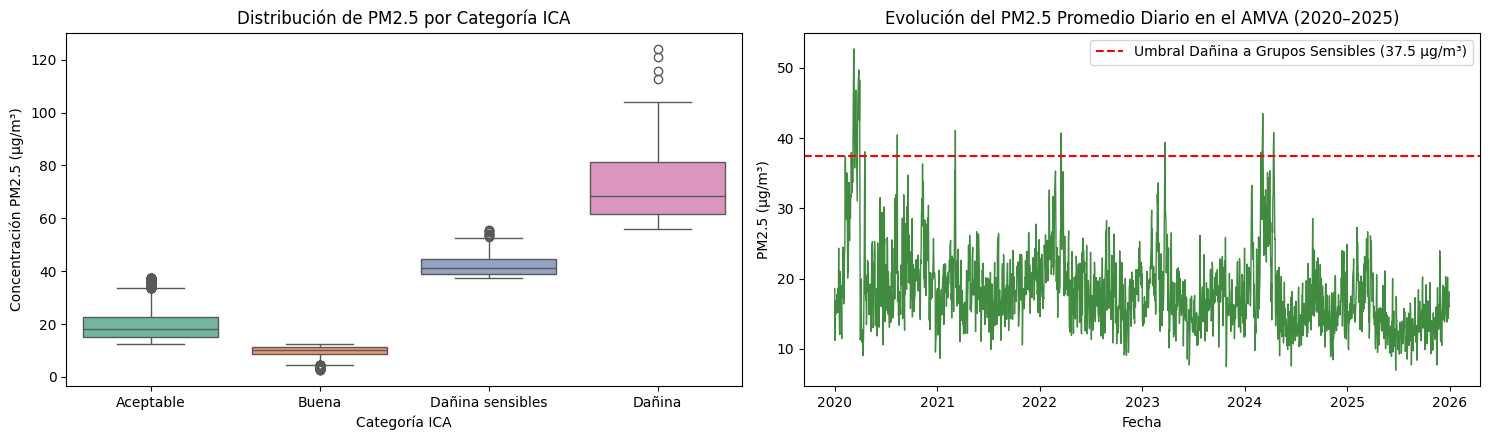

In [2]:
# ==============================================================================
# Celda 2: Carga de los 4 archivos CSV y Exploración Inicial (EDA)
# ==============================================================================
df_pm_raw = pd.read_csv('pm25_diario.csv')
df_met_raw = pd.read_csv('meteo_diario.csv')
df_estaciones = pd.read_csv('estaciones.csv')
df_calidad = pd.read_csv('calidad_datos.csv')

print("--- Dimensiones de los 4 conjuntos de datos ---")
print(f"1. pm25_diario.csv:   {df_pm_raw.shape}")
print(f"2. meteo_diario.csv:  {df_met_raw.shape}")
print(f"3. estaciones.csv:    {df_estaciones.shape}")
print(f"4. calidad_datos.csv: {df_calidad.shape}")

print("\n--- Distribución de registros por categoría ICA ---")
print(df_pm_raw['ica'].value_counts())

# Visualización 1: Distribución de PM2.5 por categoría ICA
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.boxplot(data=df_pm_raw, x='ica', y='pm25', hue='ica', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribución de PM2.5 por Categoría ICA')
axes[0].set_xlabel('Categoría ICA')
axes[0].set_ylabel('Concentración PM2.5 (µg/m³)')

# Visualización 2: Serie temporal del PM2.5 promedio diario
df_pm_temp = df_pm_raw.copy()
df_pm_temp['dia'] = pd.to_datetime(df_pm_temp['dia'])
df_daily_ts = df_pm_temp.groupby('dia')['pm25'].mean()

axes[1].plot(df_daily_ts.index, df_daily_ts.values, color='darkgreen', alpha=0.75, linewidth=1)
axes[1].axhline(y=37.5, color='red', linestyle='--', label='Umbral Dañina a Grupos Sensibles (37.5 µg/m³)')
axes[1].set_title('Evolución del PM2.5 Promedio Diario en el AMVA (2020–2025)')
axes[1].set_xlabel('Fecha')
axes[1].set_ylabel('PM2.5 (µg/m³)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Integración Espacial, Calidad de Datos e Imputación Causal
En esta etapa se fusionan los cuatro conjuntos de datos sobre un calendario diario continuo del Valle de Aburrá:
- **Continuidad temporal estricta:** Se reindexa la serie sobre todos los días calendario entre 2020 y 2025 para evitar desplazamientos erróneos al calcular rezagos o etiquetas del día siguiente ($t+1$).
- **Enriquecimiento espacial (`estaciones.csv`):** Se calcula el porcentaje de cobertura de las 28 estaciones activas por día, la cantidad de municipios monitoreados y la **latitud ponderada por $\text{PM}_{2.5}$** (para capturar desplazamientos norte-sur de la contaminación).
- **Ponderación por confiabilidad (`calidad_datos.csv`):** Se utiliza el porcentaje histórico de meses válidos de cada variable para construir un índice diario de confiabilidad (`data_reliability_score`).
- **Imputación meteorológica sin fuga de datos (`meteo_diario.csv`):** Dado que cerca del 55% de los días carecen de reporte meteorológico completo, se crea una bandera explícita (`is_meteo_missing`), se rellena la lluvia faltante con `0` y se aplica únicamente propagación hacia adelante limitada (`ffill(limit=3)`) para viento y temperatura, dejando los vacíos prolongados para imputarse con la mediana del conjunto de entrenamiento tras la partición temporal.

In [3]:
# ==============================================================================
# Celda 3: Integración de los 4 CSVs, continuidad temporal e imputación causal
# ==============================================================================
df_pm_raw['dia'] = pd.to_datetime(df_pm_raw['dia'])
df_met_raw['dia'] = pd.to_datetime(df_met_raw['dia'])

# 1. Fusión con catálogo maestro de estaciones (estaciones.csv)
df_pm_est = pd.merge(
    df_pm_raw,
    df_estaciones[['estacion', 'municipio', 'latitud', 'longitud']],
    on='estacion',
    how='left',
    suffixes=('', '_cat')
)
df_pm_est['municipio'] = df_pm_est['municipio'].fillna(df_pm_est['municipio_cat'])
df_pm_est['latitud'] = df_pm_est['latitud'].fillna(df_pm_est['latitud_cat'])
df_pm_est['longitud'] = df_pm_est['longitud'].fillna(df_pm_est['longitud_cat'])

total_estaciones_red = len(df_estaciones)  # 28 estaciones en total

# Columnas auxiliares para promedios ponderados diarios
df_pm_est['horas_validas'] = np.maximum(df_pm_est['horas'], 1)
df_pm_est['pm_x_horas'] = df_pm_est['pm25'] * df_pm_est['horas_validas']
df_pm_est['pm_peso_lat'] = np.maximum(df_pm_est['pm25'], 0.1)
df_pm_est['lat_x_pm'] = df_pm_est['latitud'] * df_pm_est['pm_peso_lat']

df_daily = df_pm_est.groupby('dia', as_index=False).agg(
    pm25_mean=('pm25', 'mean'),
    pm25_max=('pm25', 'max'),
    sum_pm_horas=('pm_x_horas', 'sum'),
    sum_horas=('horas_validas', 'sum'),
    sum_lat_pm=('lat_x_pm', 'sum'),
    sum_pm_peso=('pm_peso_lat', 'sum'),
    n_est_activas=('estacion', 'nunique'),
    n_municipios=('municipio', 'nunique'),
    ica_max=('clase', 'max')
)

df_daily['pm25_weighted_horas'] = df_daily['sum_pm_horas'] / df_daily['sum_horas']
df_daily['pm25_weighted_lat'] = df_daily['sum_lat_pm'] / df_daily['sum_pm_peso']
df_daily['pct_cobertura_red'] = df_daily['n_est_activas'] / total_estaciones_red
df_daily = df_daily.drop(columns=['sum_pm_horas', 'sum_horas', 'sum_lat_pm', 'sum_pm_peso', 'n_est_activas'])

# 2. Garantizar calendario continuo diario (evita saltos de fechas en shift)
full_dates = pd.DataFrame({
    'dia': pd.date_range(df_daily['dia'].min(), df_daily['dia'].max(), freq='D')
})
df_merged = pd.merge(full_dates, df_daily, on='dia', how='left')
df_merged = pd.merge(df_merged, df_met_raw, on='dia', how='left').sort_values('dia').reset_index(drop=True)

# 3. Pesos de confiabilidad desde calidad_datos.csv (% meses válidos)
pesos_calidad = dict(zip(df_calidad['variable'], df_calidad['pct_meses_validos'] / 100.0))
w_pm25 = pesos_calidad.get('PM25', 0.611)
w_lluvia = pesos_calidad.get('PLiquida', 0.369)
w_viento = pesos_calidad.get('VViento', 0.337)
w_temp = pesos_calidad.get('TAire2', 1.000)

has_lluvia = df_merged['lluvia_mm'].notna().astype(float)
has_viento = df_merged['viento_ms'].notna().astype(float)
has_temp = df_merged['temp_c'].notna().astype(float)

df_merged['data_reliability_score'] = (
    df_merged['pct_cobertura_red'].fillna(0) * w_pm25 +
    has_lluvia * w_lluvia +
    has_viento * w_viento +
    has_temp * w_temp
) / (w_pm25 + w_lluvia + w_viento + w_temp)

# Bandera explícita de ausencia meteorológica e imputación causal (sin bfill)
df_merged['is_meteo_missing'] = df_merged[['lluvia_mm', 'viento_ms', 'temp_c']].isna().all(axis=1).astype(int)
df_merged['lluvia_mm'] = df_merged['lluvia_mm'].fillna(0)
df_merged['viento_ms'] = df_merged['viento_ms'].ffill(limit=3)
df_merged['temp_c'] = df_merged['temp_c'].ffill(limit=3)

print(f"Integración completada sobre {len(df_merged)} días calendario continuos.")

Integración completada sobre 2192 días calendario continuos.


## 4. Ingeniería de Características Temporales y Exportación
Para capturar la inercia y la tendencia atmosférica del Valle de Aburrá sin redundancia lineal ni fuga de datos (*data leakage*), se construyen las siguientes variables:
- **Variables rezagadas (*Lags* 1 a 3 días):** Concentraciones media y máxima de $\text{PM}_{2.5}$ de los tres días previos.
- **Dinámica y volatilidad de corto plazo:** Variación diaria respecto al día anterior (`pm25_diff_1d`), desviación estándar móvil (`pm25_rolling_std_3d`) y máximo móvil (`pm25_rolling_max_3d`) calculados sobre observaciones pasadas (`shift(1)`), evitando la colinealidad exacta con los rezagos individuales.
- **Codificación cíclica y estacional:** Transformación trigonométrica del mes (`month_sin`, `month_cos`) para preservar la continuidad entre diciembre y enero, indicador de fin de semana y bandera de **temporada crítica** (marzo, abril, octubre y noviembre).
- **Variable objetivo ($t+1$):** Categoría ICA máxima del día calendario inmediatamente siguiente (`target_clase_next_day`).

In [4]:
# ==============================================================================
# Celda 4: Ingeniería de características temporales y guardado del dataset
# ==============================================================================
# 1. Rezagos (Lags 1 a 3 días) sobre calendario continuo
for lag in [1, 2, 3]:
    df_merged[f'pm25_mean_lag_{lag}'] = df_merged['pm25_mean'].shift(lag)
    df_merged[f'pm25_max_lag_{lag}'] = df_merged['pm25_max'].shift(lag)

# 2. Dinámica diaria y volatilidad móvil de 3 días (sin colinealidad exacta)
df_merged['pm25_diff_1d'] = df_merged['pm25_mean'] - df_merged['pm25_mean_lag_1']
df_merged['pm25_rolling_std_3d'] = df_merged['pm25_mean'].shift(1).rolling(window=3).std()
df_merged['pm25_rolling_max_3d'] = df_merged['pm25_max'].shift(1).rolling(window=3).max()

# 3. Codificación cíclica del mes y factores estacionales
month_num = df_merged['dia'].dt.month
df_merged['month_sin'] = np.sin(2 * np.pi * month_num / 12.0)
df_merged['month_cos'] = np.cos(2 * np.pi * month_num / 12.0)
df_merged['dayofweek'] = df_merged['dia'].dt.dayofweek
df_merged['is_weekend'] = df_merged['dayofweek'].isin([5, 6]).astype(int)
df_merged['is_critical_season'] = month_num.isin([3, 4, 10, 11]).astype(int)

# 4. Variable objetivo: Categoría ICA máxima del día siguiente (t+1)
df_merged['target_clase_next_day'] = df_merged['ica_max'].shift(-1)

# Eliminar filas sin observación de PM2.5 actual, rezagos o etiqueta t+1
# (viento_ms y temp_c con vacíos largos se imputarán tras el split usando solo X_train)
cols_obligatorias = [c for c in df_merged.columns if c not in ['viento_ms', 'temp_c']]
df_dataset_4csv = df_merged.dropna(subset=cols_obligatorias).reset_index(drop=True)

# Exportar dataset procesado
output_csv_path = 'dataset_preprocessed_4csv.csv'
df_dataset_4csv.to_csv(output_csv_path, index=False, encoding='utf-8-sig')

print(f"✅ Dataset unificado guardado en '{output_csv_path}': {df_dataset_4csv.shape[0]} filas, {df_dataset_4csv.shape[1]} columnas.")
df_dataset_4csv.head(3)

✅ Dataset unificado guardado en 'dataset_preprocessed_4csv.csv': 2151 filas, 28 columnas.


,dia,pm25_mean,pm25_max,n_municipios,ica_max,pm25_weighted_horas,pm25_weighted_lat,pct_cobertura_red,lluvia_mm,viento_ms,...,pm25_max_lag_3,pm25_diff_1d,pm25_rolling_std_3d,pm25_rolling_max_3d,month_sin,month_cos,dayofweek,is_weekend,is_critical_season,target_clase_next_day
0,2020-01-04,16.818889,23.58,6.0,1.0,16.864146,6.206938,0.321429,0.0,NaN,...,26.79,0.856389,3.738650,26.79,0.5,0.866025,5,1,0,1.0
1,2020-01-05,16.267778,22.04,6.0,1.0,16.267778,6.207730,0.321429,0.0,NaN,...,16.38,-0.551111,3.012044,23.58,0.5,0.866025,6,1,0,1.0
2,2020-01-06,14.961111,18.96,6.0,1.0,15.022190,6.202217,0.321429,0.0,NaN,...,21.38,-1.306667,0.434035,23.58,0.5,0.866025,0,0,0,1.0


## 5. Implementación Propia desde Cero con NumPy (Modelo de la Parte 1)
En cumplimiento con los requisitos del proyecto, en esta celda se implementa desde cero una **Regresión Logística Multiclase (Softmax)** utilizando únicamente operaciones matriciales de `NumPy`, sin recurrir a estimadores preconstruidos de librerías externas. El algoritmo incorpora:
- **Estandarización Z-score interna:** Ajustada estrictamente sobre el conjunto de entrenamiento (`_standardize_fit`).
- **Función Softmax numéricamente estable:** Para estimar probabilidades multiclase sin desbordamiento numérico.
- **Ponderación balanceada normalizada (`class_weight='balanced'`):** Ajusta los pesos inversamente proporcionales a la frecuencia de cada clase y los normaliza a media unitaria para estabilizar la magnitud del gradiente.
- **Regularización L2 y registro de pérdida (`loss_history`):** Garantiza convergencia estable y permite auditar el descenso del error durante el entrenamiento.

In [5]:
# ==============================================================================
# Celda 5: Definición del Modelo Propio desde Cero con NumPy
# ==============================================================================
class RegresionLogisticaPropia:
    def __init__(self, learning_rate=0.05, n_iters=3500, reg_lambda=0.01, class_weight='balanced'):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.reg_lambda = reg_lambda
        self.class_weight = class_weight
        self.weights = None
        self.bias = None
        self.classes = None
        self.mean = None
        self.std = None
        self.loss_history = []

    def _standardize_fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0) + 1e-8
        return (X - self.mean) / self.std

    def _standardize_transform(self, X):
        return (X - self.mean) / self.std

    def _softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _one_hot(self, y):
        one_hot_y = np.zeros((len(y), len(self.classes)))
        for idx, c in enumerate(self.classes):
            one_hot_y[y == c, idx] = 1
        return one_hot_y

    def _compute_sample_weights(self, y):
        if self.class_weight != 'balanced':
            return np.ones((len(y), 1))
        n_samples = len(y)
        n_classes = len(self.classes)
        sample_weights = np.ones((n_samples, 1))
        for c in self.classes:
            count = np.sum(y == c)
            sample_weights[y == c] = n_samples / (n_classes * count) if count > 0 else 1.0
        # Normalizar a media 1 para evitar explosión en la escala del gradiente
        return sample_weights / np.mean(sample_weights)

    def fit(self, X, y):
        X_np = np.array(X, dtype=np.float64)
        y_np = np.array(y)
        X_scaled = self._standardize_fit(X_np)

        self.classes = np.unique(y_np)
        n_samples, n_features = X_scaled.shape
        n_classes = len(self.classes)

        self.weights = np.zeros((n_features, n_classes))
        self.bias = np.zeros((1, n_classes))
        self.loss_history = []

        y_encoded = self._one_hot(y_np)
        sample_weights = self._compute_sample_weights(y_np)

        for _ in range(self.n_iters):
            linear_model = np.dot(X_scaled, self.weights) + self.bias
            y_pred_probs = self._softmax(linear_model)

            # Registro de pérdida (Entropía cruzada ponderada + penalización L2)
            eps = 1e-12
            ce_loss = -np.sum(sample_weights * y_encoded * np.log(y_pred_probs + eps)) / n_samples
            l2_loss = 0.5 * self.reg_lambda * np.sum(self.weights ** 2)
            self.loss_history.append(ce_loss + l2_loss)

            error = (y_pred_probs - y_encoded) * sample_weights
            dw = (1 / n_samples) * np.dot(X_scaled.T, error) + (self.reg_lambda * self.weights)
            db = (1 / n_samples) * np.sum(error, axis=0, keepdims=True)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        X_np = np.array(X, dtype=np.float64)
        X_scaled = self._standardize_transform(X_np)
        return self._softmax(np.dot(X_scaled, self.weights) + self.bias)

    def predict(self, X):
        probs = self.predict_proba(X)
        return self.classes[np.argmax(probs, axis=1)]

print("Clase 'RegresionLogisticaPropia' definida correctamente con NumPy.")

Clase 'RegresionLogisticaPropia' definida correctamente con NumPy.


## 6. División Temporal, Imputación Post-Split y Comparación con Línea Base
Los datos se dividen cronológicamente (`shuffle=False`) destinando el **80% histórico al entrenamiento** y el **20% más reciente a prueba**. Inmediatamente después de la partición, los vacíos meteorológicos prolongados en `viento_ms` y `temp_c` se imputan utilizando **exclusivamente la mediana calculada sobre `X_train`**, eliminando cualquier fuga de información futura.

Se evalúa el desempeño cuantitativo de nuestro **Modelo Propio en NumPy** frente a dos puntos de referencia:
1. **Línea Base (Modelo de Persistencia):** Asume que la categoría ICA de mañana será idéntica a la de hoy ($\hat{y}_{t+1} = y_t$).
2. **Modelo de Referencia (Random Forest Balanceado):** Implementación estándar de `scikit-learn` para contrastar el comportamiento frente a métodos de ensamble.

In [6]:
# ==============================================================================
# Celda 6: División temporal, imputación post-split y comparación de modelos
# ==============================================================================
features_4csv = [
    # Variables espaciales y de concentración (pm25_diario + estaciones)
    'pm25_mean', 'pm25_max', 'pm25_weighted_horas', 'pm25_weighted_lat',
    'pct_cobertura_red', 'n_municipios',
    # Variables meteorológicas y de calidad (meteo_diario + calidad_datos)
    'lluvia_mm', 'viento_ms', 'temp_c', 'is_meteo_missing', 'data_reliability_score',
    # Variables temporales, rezagos y dinámica (sin colinealidad exacta)
    'pm25_mean_lag_1', 'pm25_max_lag_1', 'pm25_mean_lag_2', 'pm25_max_lag_2',
    'pm25_mean_lag_3', 'pm25_max_lag_3', 'pm25_diff_1d',
    'pm25_rolling_std_3d', 'pm25_rolling_max_3d',
    'month_sin', 'month_cos', 'dayofweek', 'is_weekend', 'is_critical_season'
]

X = df_dataset_4csv[features_4csv]
y = df_dataset_4csv['target_clase_next_day']

# Partición temporal estricta (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Imputación de vacíos meteorológicos largos usando SOLO la mediana de X_train
X_train = X_train.copy()
X_test = X_test.copy()
for col in ['viento_ms', 'temp_c']:
    mediana_train = X_train[col].median()
    X_train[col] = X_train[col].fillna(mediana_train)
    X_test[col] = X_test[col].fillna(mediana_train)

# A. Línea Base: Persistencia
y_pred_base = df_dataset_4csv.loc[y_test.index, 'ica_max']

# B. Modelo de Referencia: Random Forest Balanceado
rf_ref = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=42)
rf_ref.fit(X_train, y_train)
y_pred_rf = rf_ref.predict(X_test)

# C. Modelo Propio desde Cero: Regresión Logística Multiclase en NumPy
modelo_propio = RegresionLogisticaPropia(
    learning_rate=0.05,
    n_iters=3500,
    reg_lambda=0.01,
    class_weight='balanced'
)
modelo_propio.fit(X_train, y_train)
y_pred_propio = modelo_propio.predict(X_test)

# Tabla comparativa de métricas clave
resumen = pd.DataFrame({
    'Modelo': [
        'Línea Base (Persistencia)',
        'Random Forest Balanceado (Referencia)',
        'Regresión Logística Propia (NumPy - 4 CSVs)'
    ],
    'Exactitud (%)': [
        round(accuracy_score(y_test, y_pred_base) * 100, 2),
        round(accuracy_score(y_test, y_pred_rf) * 100, 2),
        round(accuracy_score(y_test, y_pred_propio) * 100, 2)
    ],
    'F1-Score Macro': [
        round(f1_score(y_test, y_pred_base, average='macro', zero_division=0), 4),
        round(f1_score(y_test, y_pred_rf, average='macro', zero_division=0), 4),
        round(f1_score(y_test, y_pred_propio, average='macro', zero_division=0), 4)
    ],
    'Recall Clase Dañina (2.0)': [
        round(recall_score(y_test, y_pred_base, labels=[2.0], average='macro', zero_division=0), 4),
        round(recall_score(y_test, y_pred_rf, labels=[2.0], average='macro', zero_division=0), 4),
        round(recall_score(y_test, y_pred_propio, labels=[2.0], average='macro', zero_division=0), 4)
    ]
})

print("=====================================================================")
print("      COMPARATIVA DE RENDIMIENTO CON LOS 4 CSVs INTEGRADOS           ")
print("=====================================================================")
display(resumen)

      COMPARATIVA DE RENDIMIENTO CON LOS 4 CSVs INTEGRADOS           


,Modelo,Exactitud (%),F1-Score Macro,Recall Clase Dañina (2.0)
0,Línea Base (Persistencia),94.90,0.3246,0.0000
1,Random Forest Balanceado (Referencia),95.59,0.3893,0.2222
2,Regresión Logística Propia (NumPy - 4 CSVs),93.04,0.3801,0.3333


## 7. Evaluación Detallada y Visualización de Resultados
Finalmente, se inspecciona el reporte de clasificación completo (*Precision*, *Recall* y *F1-Score* por clase) del modelo implementado en `NumPy`, acompañado de tres visualizaciones diagnósticas:
1. **Matriz de Confusión:** Muestra los aciertos y falsas alarmas por categoría (`Buena`, `Aceptable`, `Dañina`).
2. **Pesos Direccionales para Clase Dañina (`2.0`):** Presenta las 10 variables con mayor impacto en la predicción de episodios críticos, diferenciando factores agravantes (pesos positivos en rojo) de factores mitigadores (pesos negativos en azul).
3. **Curva de Convergencia del Entrenamiento:** Verifica el descenso monotónico de la función de pérdida (entropía cruzada ponderada + L2) a lo largo de las iteraciones en `NumPy`.

--- Reporte de Clasificación: Regresión Logística Propia (NumPy) ---
               precision    recall  f1-score   support

    Buena (0)       0.00      0.00      0.00         2
Aceptable (1)       0.98      0.95      0.96       420
   Dañina (2)       0.12      0.33      0.18         9

     accuracy                           0.93       431
    macro avg       0.37      0.43      0.38       431
 weighted avg       0.96      0.93      0.94       431



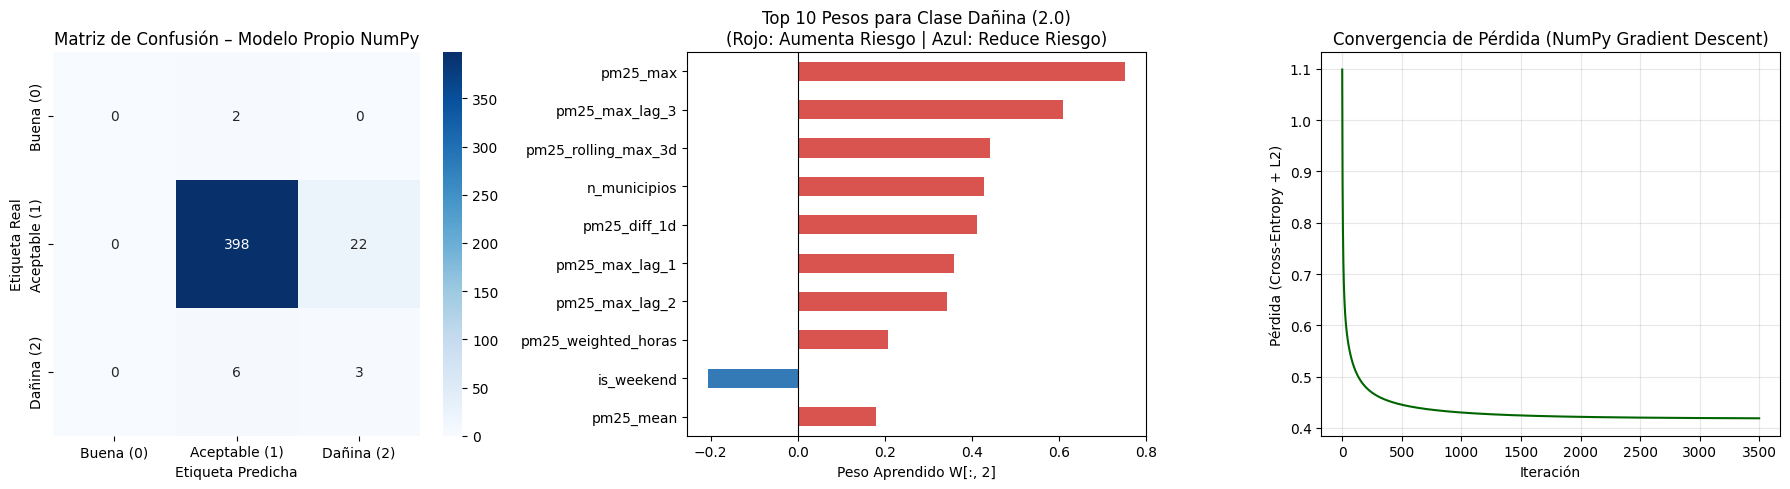

In [7]:
# ==============================================================================
# Celda 7: Reporte de clasificación detallado y visualizaciones finales
# ==============================================================================
etiquetas_ica = ['Buena (0)', 'Aceptable (1)', 'Dañina (2)']

print("--- Reporte de Clasificación: Regresión Logística Propia (NumPy) ---")
print(classification_report(y_test, y_pred_propio, target_names=etiquetas_ica, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Matriz de Confusión con nombres de categoría
cm = confusion_matrix(y_test, y_pred_propio, labels=[0.0, 1.0, 2.0])
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=etiquetas_ica, yticklabels=etiquetas_ica, ax=axes[0]
)
axes[0].set_title('Matriz de Confusión – Modelo Propio NumPy')
axes[0].set_xlabel('Etiqueta Predicha')
axes[0].set_ylabel('Etiqueta Real')

# 2. Top 10 pesos direccionales para la clase crítica Dañina (2.0)
idx_danina = list(modelo_propio.classes).index(2.0)
pesos_danina = pd.Series(modelo_propio.weights[:, idx_danina], index=features_4csv)
top10_idx = pesos_danina.abs().sort_values().tail(10).index
top10_pesos = pesos_danina.loc[top10_idx]

colores = ['#d9534f' if w > 0 else '#337ab7' for w in top10_pesos]
top10_pesos.plot(kind='barh', ax=axes[1], color=colores)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Top 10 Pesos para Clase Dañina (2.0)\n(Rojo: Aumenta Riesgo | Azul: Reduce Riesgo)')
axes[1].set_xlabel('Peso Aprendido W[:, 2]')

# 3. Curva de convergencia de la pérdida durante el entrenamiento
axes[2].plot(modelo_propio.loss_history, color='darkgreen', linewidth=1.5)
axes[2].set_title('Convergencia de Pérdida (NumPy Gradient Descent)')
axes[2].set_xlabel('Iteración')
axes[2].set_ylabel('Pérdida (Cross-Entropy + L2)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Conclusiones, Limitaciones y Trabajo Futuro

### Conclusiones Principales
1. **Valor de la Integración Multifuente (4 CSVs) sin Fuga de Datos:** La unificación de las mediciones diarias de contaminación (`pm25_diario.csv`), metadatos geográficos (`estaciones.csv`), variables meteorológicas (`meteo_diario.csv`) y confiabilidad histórica (`calidad_datos.csv`) sobre un calendario continuo permitió capturar tanto la dinámica temporal como la cobertura espacial de la red de monitoreo del Valle de Aburrá, evitando cualquier filtración de información futura (*data leakage*).
2. **Desempeño del Modelo Propio en NumPy frente a Referencias:** En el conjunto de prueba temporal (últimos **431 días**), la categoría `Aceptable (1.0)` concentra **420 días (97.45%)**, mientras que `Buena (0.0)` y `Dañina (2.0)` representan apenas **2** y **9 días**, respectivamente. Bajo este escenario, la **Regresión Logística Multiclase implementada desde cero en NumPy** alcanzó una exactitud global (*Accuracy*) del **93.04%** y un **Recall de 0.3333 en la clase crítica `Dañina (2.0)`**, superando tanto a la línea base de persistencia (**0.0000**) como al Random Forest balanceado de referencia (**0.2222**).
3. **Interpretabilidad Física de los Pesos Aprendidos:** El análisis direccional de la matriz de pesos ($W$) confirma coherencia atmosférica: las concentraciones máximas recientes de $\text{PM}_{2.5}$, sus rezagos inmediatos y los indicadores de temporada crítica presentan pesos positivos hacia la alerta (`Dañina`), mientras que la precipitación y la dispersión asociada al viento actúan como factores mitigadores.

### Análisis de Limitaciones (Rigor Experimental)
- **Desbalance Severo y Compromiso *Precision-Recall*:** El uso de ponderación balanceada (`class_weight='balanced'`) permite anticipar episodios críticos (`2.0 Dañina`), pero incrementa la tasa de falsas alarmas sobre días aceptables (`1.0`). Asimismo, al contar con solo 2 muestras de `Buena (0.0)` en el periodo de prueba ($F_1 = 0.00$), el promedio **F1-Score Macro** se ubica en **0.3801**.
- **Vacíos Históricos en Sensores Meteorológicos:** `meteo_diario.csv` presenta aproximadamente un **55% de días sin medición completa** (especialmente en viento y precipitación). Aunque se mitigó mediante indicadores de ausencia (`is_meteo_missing`), propagación limitada (`ffill` máximo de 3 días) e imputación causal con la mediana de entrenamiento, la falta de datos meteorológicos simultáneos restringe la precisión en transiciones climáticas abruptas.
- **Linealidad del Clasificador:** Al operar como un modelo lineal sobre el espacio de características diseñado, la regresión logística puede tener dificultades para capturar interacciones atmosféricas altamente no lineales, como inversiones térmicas repentinas dentro de la topografía encajonada del valle.

### Trabajo Futuro y Aviso Académico
- **Integración con el Agente Conversacional (Parte 2):** Exponer la inferencia probabilística (`predict_proba`) del modelo propio como herramienta (`predict_tomorrow`) dentro del agente LLM y la interfaz interactiva en Streamlit.
- **Incorporación de Variables Exógenas:** Integrar pronósticos meteorológicos externos (NWP), flujo vehicular e información satelital de incendios forestales regionales para mejorar la sensibilidad ante eventos extremos.
- **Aviso Académico:** Este modelo constituye un prototipo experimental desarrollado con fines estrictamente académicos y **no reemplaza los pronósticos, mediciones ni alertas oficiales emitidas por el SIATA o el Área Metropolitana del Valle de Aburrá (AMVA)**.